# 06 — ResNet-50 dan ensemble lintas arsitektur
Ensemble EfficientNet 224/320 sebelumnya mendapat skor leaderboard **0,86491**, dilaporkan pengguna pada 28 Oktober 2026. Kelas lemah pada validasi mencakup scientific_report, presentation, dan form. Hipotesis eksperimen: fitur dari backbone berbeda dapat mengurangi kesalahan bersama kedua EfficientNet.

ResNet-50 dimulai dari [bobot ImageNet-1K V2 resmi Torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html), bukan dari checkpoint kompetisi eksternal. Model hanya menerima piksel. Split yang sama dipakai untuk semua komponen; duplikat persis tidak melintasi train/validasi.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/resnet_diversity'
SELECTED = ROOT / 'reports/diversity_selection'
display(pd.read_json(ROOT / 'reports/leaderboard_history.json'))
display(pd.read_csv(ROOT / 'reports/highres_selection/classification_report.csv', index_col=0).iloc[:16].sort_values('f1-score').head())

,reported_on,run_name,submission,submission_sha256,score,score_source,leaderboard_partition,metric_name
0,2026-10-27,baseline_cnn,submissions/submission_baseline.csv,5fd9913aedf081fdb66e9823eb28e36e6146162113f3d1...,0.67294,Reported by user in chat,unspecified,unverified
1,2026-10-28,efficientnet_improved,submissions/submission_improved.csv,2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80...,0.85236,Reported by user in chat,unspecified,unverified
2,2026-10-28,highres_selection,submissions/submission_highres_selected.csv,9a2231e16ba635ae4f99aa8f74fe8ed5efd46853e856fc...,0.86491,Reported by user in chat,unspecified,unverified


,precision,recall,f1-score,support
scientific_report,0.716381,0.716381,0.716381,409.0
presentation,0.719128,0.751899,0.735149,395.0
form,0.726098,0.753351,0.739474,373.0
budget,0.839050,0.817481,0.828125,389.0
questionnaire,0.829897,0.838542,0.834197,384.0


## Preprocessing dan training
Gambar letterbox 224×224 mempertahankan rasio halaman dan padding putih. Grayscale direplikasi menjadi tiga kanal lalu dinormalisasi ImageNet. Augmentasi training: kontras, rotasi maksimum 1,5°, translasi maksimum 1,5%, dan skala 0,97–1,03; tanpa flip. Validasi tidak memakai augmentasi acak.

Semua layer di-fine-tune dengan AdamW, LR 0,0002, cosine schedule, label smoothing 0,05, batch 32, maksimal 10 epoch, patience 4. Checkpoint dipilih berdasarkan accuracy holdout. Perubahan arsitektur dan jadwal latihan tidak diisolasi; ini bukan ablation study.

Reproduksi: `python -m scripts.train --config configs/resnet_diversity.json --device cuda`. Gunakan environment CUDA yang dijelaskan pada README.

In [2]:
display(json.loads((ROOT / 'configs/resnet_diversity.json').read_text()))
display(json.loads((RUN / 'run.json').read_text()))
display(pd.read_csv(RUN / 'history.csv'))
display(Markdown((RUN / 'interpretation.md').read_text(encoding='utf-8')))

{'run_name': 'resnet_diversity',
 'model': 'resnet50',
 'pretrained': True,
 'image_size': 224,
 'epochs': 10,
 'batch_size': 32,
 'learning_rate': 0.0002,
 'weight_decay': 0.01,
 'label_smoothing': 0.05,
 'patience': 4,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 2,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy',
 'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}}

{'config': {'run_name': 'resnet_diversity',
  'model': 'resnet50',
  'pretrained': True,
  'image_size': 224,
  'epochs': 10,
  'batch_size': 32,
  'learning_rate': 0.0002,
  'weight_decay': 0.01,
  'label_smoothing': 0.05,
  'patience': 4,
  'seed': 42,
  'validation_fraction': 0.2,
  'workers': 2,
  'threads': 4,
  'amp': True,
  'selection_metric': 'accuracy',
  'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}},
 'device': 'cuda',
 'versions': {'torch': '2.11.0+cu128',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.7',
  'torchvision': '0.26.0+cu128'},
 'initialization': None,
 'device_name': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'train_rows': 25607,
 'validation_rows': 6395,
 'metadata_digest': '7d3d83196e1e9ae8aad8d980fbe579e496da5999e2e36f2622f0eeb4d08b179e',
 'parameter_count': 23540816}

,epoch,train_loss,val_loss,accuracy,macro_f1,learning_rate,seconds
0,1,1.250471,0.781440,0.773417,0.767389,0.000200,176.203382
1,2,0.879303,0.641263,0.817045,0.817176,0.000195,123.288943
2,3,0.740304,0.603762,0.826427,0.825461,0.000181,122.417112
3,4,0.629458,0.569129,0.842377,0.841730,0.000159,120.934187
4,5,0.530309,0.544122,0.849414,0.847556,0.000131,120.640700
5,6,0.444890,0.565182,0.851446,0.850103,0.000100,119.422958
6,7,0.388499,0.564827,0.858170,0.857377,0.000069,119.801983
7,8,0.359441,0.540899,0.861142,0.860048,0.000041,119.714776
8,9,0.344649,0.532931,0.864113,0.863364,0.000019,119.468932
9,10,0.339414,0.538850,0.859891,0.859290,0.000005,119.955520


### Eksperimen `resnet_diversity`

| Metrik | Hasil |
| --- | ---: |
| Accuracy validasi | 86.4113% |
| Macro-F1 validasi | 0.863364 |
| Majority-class baseline accuracy | 6.5676% |
| Halaman training / validasi | 25,607 / 6,395 |
| Epoch terbaik / epoch dijalankan | 9 / 10 |
| Waktu loop training + validasi | 21.0 menit |
| Perangkat | cuda |
| Skor leaderboard | Belum tersedia |

Kelas dengan F1 tertinggi: `email` (0.980), `handwritten` (0.939), `resume` (0.922).
Kelas dengan F1 terendah: `scientific_report` (0.711), `presentation` (0.737), `form` (0.750).

Kesalahan terbanyak (aktual → prediksi): `presentation` → `scientific_report` (35 halaman); `scientific_report` → `presentation` (32 halaman); `news_article` → `presentation` (20 halaman).

Accuracy validasi per epoch berkisar 77.34%–86.41%. Checkpoint dipilih berdasarkan metrik holdout pada konfigurasi. Training loss memakai label smoothing sedangkan validation loss tidak, sehingga nilai absolut keduanya tidak sepenuhnya sebanding.

Hasil ini mengukur satu holdout dengan pemisahan duplikat persis. Holdout juga dipakai untuk memilih checkpoint, sehingga skor dapat optimistis setelah tuning. Skor tersebut bukan public/private leaderboard.

Model `resnet50` menggunakan resolusi 224×224. Kemiripan layout adalah hipotesis penyebab kesalahan, bukan kesimpulan kausal dari confusion matrix. Periksa kelas lemah dan contoh halaman sebelum menentukan eksperimen berikutnya.

Artefak: [metrics](metrics.json), [history](history.csv), [split](split.csv), dan [interpretasi lengkap](interpretation.md).

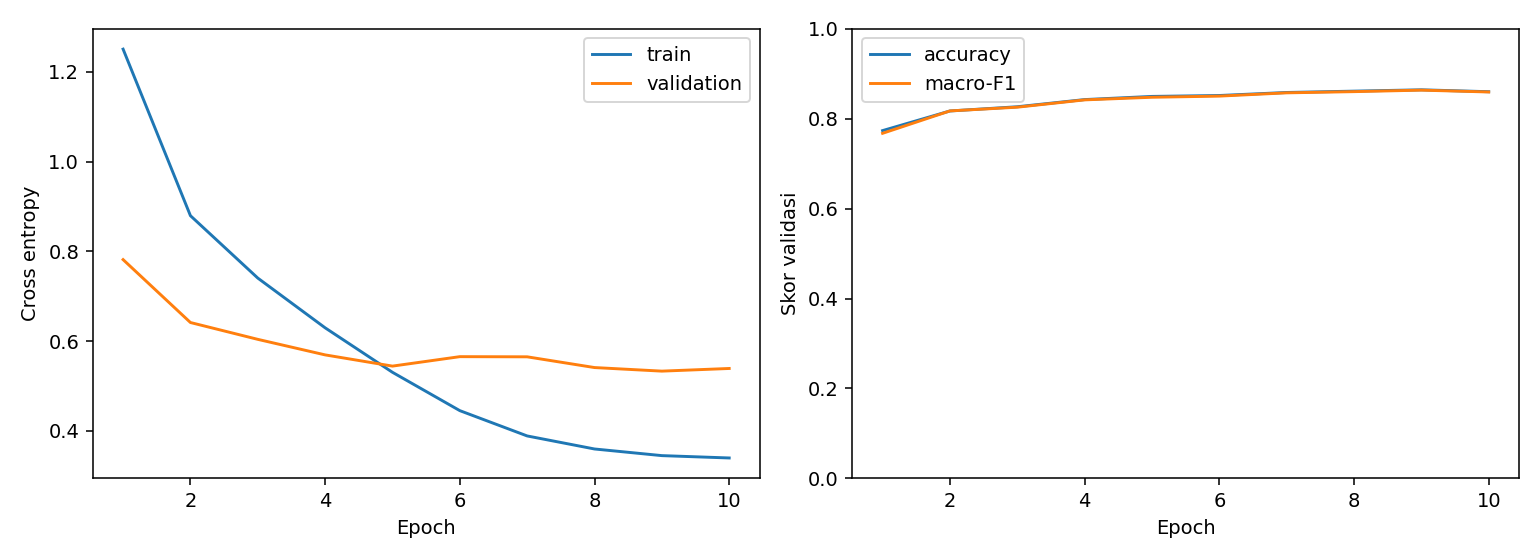

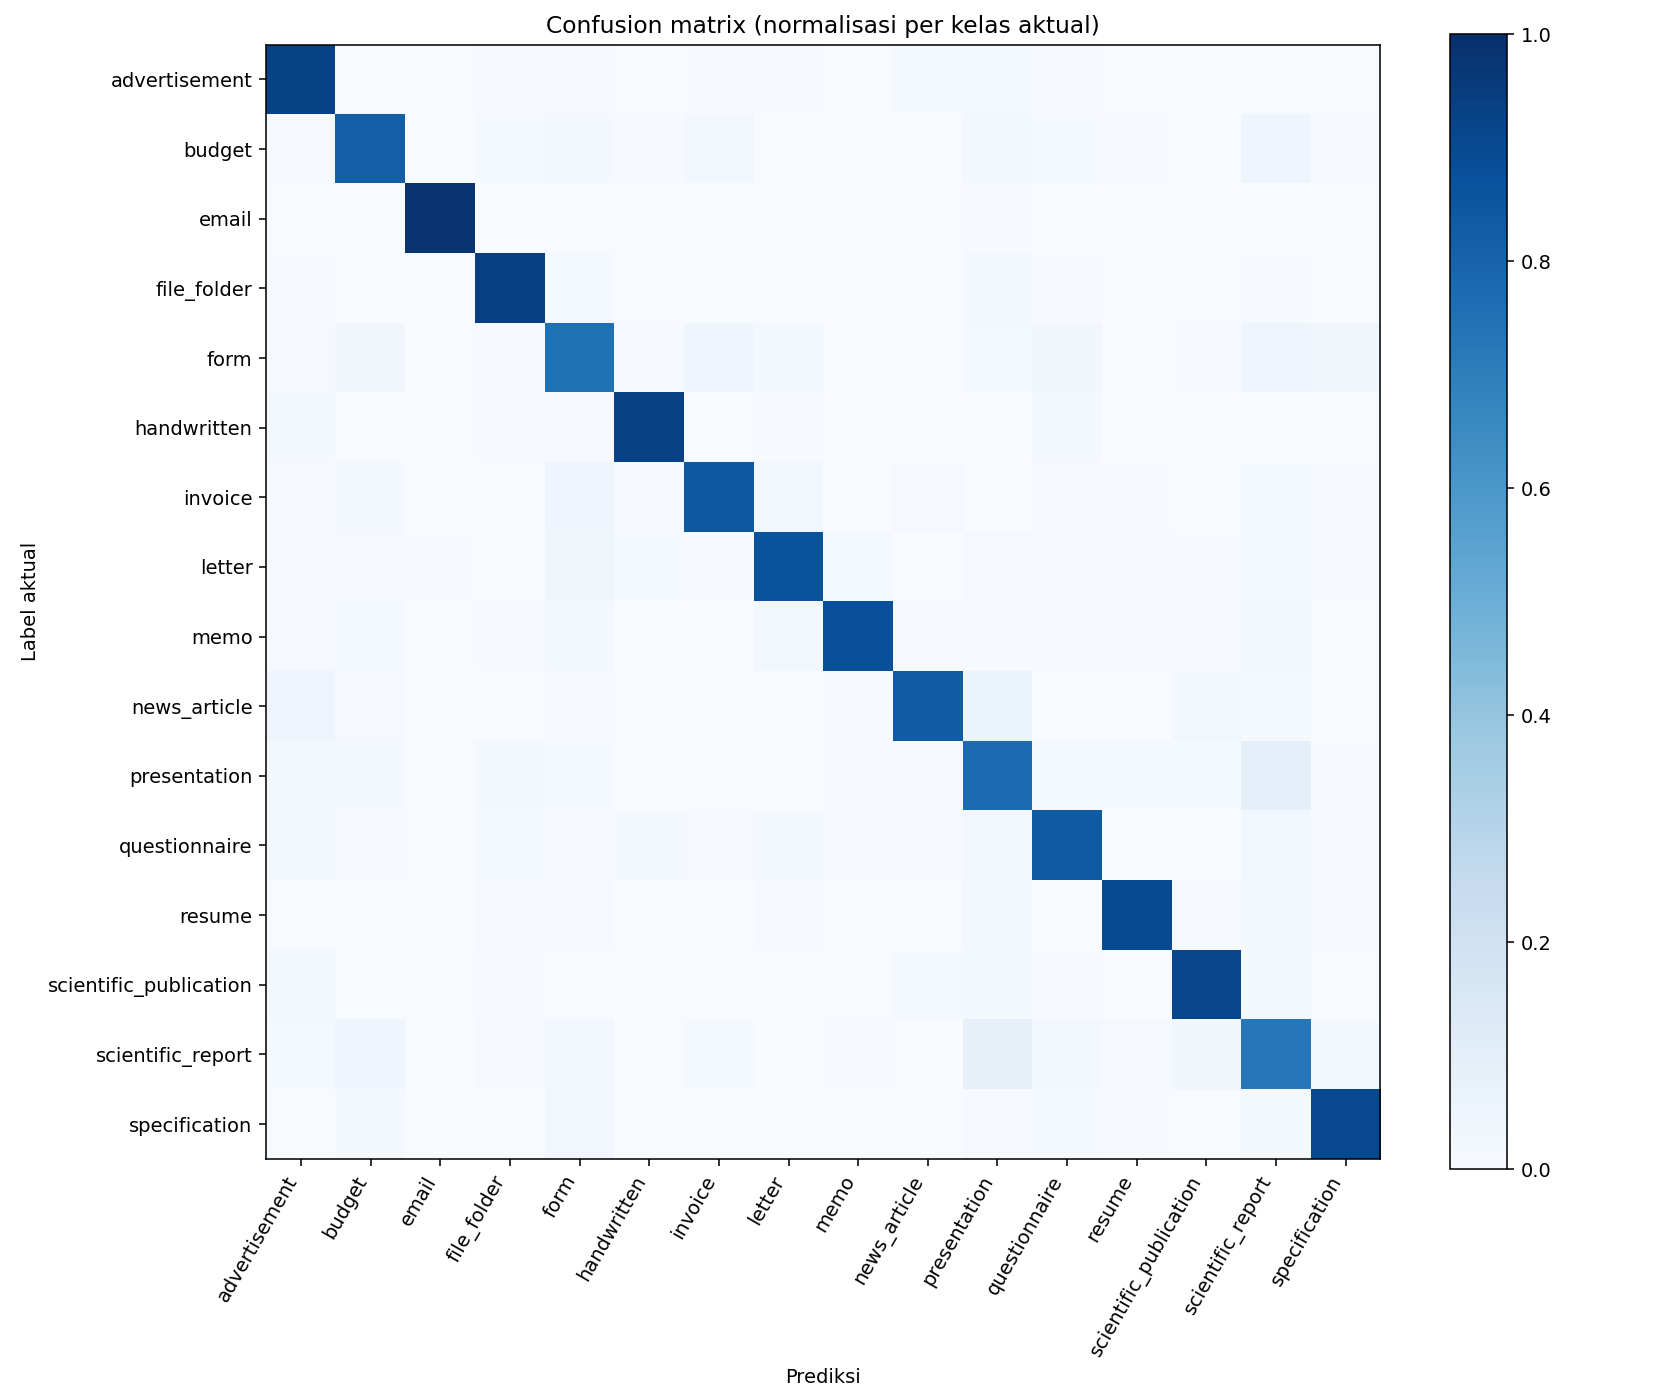

,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_11077,train/memo/0000021377.tif,memo,8,10,presentation,0.984489
1,train_28507,train/invoice/520761472+-1478.tif,invoice,6,7,letter,0.984429
2,train_20057,train/invoice/506372665_506372700.tif,invoice,6,7,letter,0.982001
3,train_16490,train/resume/1000023971_1000023973.tif,resume,12,14,scientific_report,0.981169
4,train_04715,train/budget/2063208743_8745.tif,budget,1,6,invoice,0.980318
5,train_13846,train/scientific_report/2056304711.tif,scientific_report,14,1,budget,0.980108
6,train_25513,train/invoice/508729058.tif,invoice,6,4,form,0.978088
7,train_08684,train/questionnaire/98968146_8149.tif,questionnaire,11,14,scientific_report,0.974788
8,train_30181,train/letter/522691454+-1454.tif,letter,7,4,form,0.974291
9,train_17572,train/scientific_report/2500013473.tif,scientific_report,14,1,budget,0.973123


In [3]:
display(Image(filename=str(RUN / 'learning_curves.png')))
display(Image(filename=str(RUN / 'confusion_matrix.png')))
display(pd.read_csv(RUN / 'confident_errors.csv').head(10))

## Kandidat ensemble yang ditetapkan sebelum training
Urutan komponen adalah EfficientNet 224, EfficientNet 320, dan ResNet 224. Kandidat: ensemble lama [0,5; 0,5; 0], ResNet tunggal [0; 0; 1], dan gabungan [0,25; 0,25; 0,5]. Pilih accuracy tertinggi; jika seri, pilih kandidat yang lebih awal. Tidak ada grid search bobot atau bobot per kelas.

Cache probabilitas diselaraskan berdasarkan ID. Pipeline memeriksa class mapping, fingerprint metadata, split, hash checkpoint test, serta kesesuaian prediksi validasi dengan laporan. Arsip validasi lama belum menyimpan hash checkpoint; arsip baru menyimpannya. Keterbatasan provenance arsip lama dicatat pada selection.json.

In [4]:
selection = json.loads((SELECTED / 'selection.json').read_text())
display(json.loads((ROOT / 'configs/diversity_selection.json').read_text()))
display(pd.read_csv(SELECTED / 'candidates.csv'))
display(selection)
display(Markdown((SELECTED / 'interpretation.md').read_text(encoding='utf-8')))
previous = pd.read_csv(ROOT / 'reports/highres_selection/classification_report.csv', index_col=0).iloc[:16]
current = pd.read_csv(SELECTED / 'classification_report.csv', index_col=0).loc[previous.index]
comparison = pd.DataFrame({'previous_f1': previous['f1-score'], 'selected_f1': current['f1-score']})
comparison['delta_f1'] = comparison.selected_f1 - comparison.previous_f1
display(comparison.sort_values('delta_f1'))

{'experiment': 'diversity_selection',
 'runs': ['efficientnet_improved', 'efficientnet_highres', 'resnet_diversity'],
 'candidates': [{'variant': 'previous_ensemble', 'weights': [0.5, 0.5, 0.0]},
  {'variant': 'resnet_single', 'weights': [0.0, 0.0, 1.0]},
  {'variant': 'diverse_blend', 'weights': [0.25, 0.25, 0.5]}],
 'selection_rule': 'Highest holdout accuracy; ties prefer the first listed candidate',
 'submission': 'submissions/submission_diversity_selected.csv'}

,variant,weights,accuracy,macro_f1
0,previous_ensemble,"[0.5, 0.5, 0.0]",0.865207,0.864017
1,resnet_single,"[0.0, 0.0, 1.0]",0.864113,0.863364
2,diverse_blend,"[0.25, 0.25, 0.5]",0.876310,0.875485


{'config': {'experiment': 'diversity_selection',
  'runs': ['efficientnet_improved',
   'efficientnet_highres',
   'resnet_diversity'],
  'candidates': [{'variant': 'previous_ensemble', 'weights': [0.5, 0.5, 0.0]},
   {'variant': 'resnet_single', 'weights': [0.0, 0.0, 1.0]},
   {'variant': 'diverse_blend', 'weights': [0.25, 0.25, 0.5]}],
  'selection_rule': 'Highest holdout accuracy; ties prefer the first listed candidate',
  'submission': 'submissions/submission_diversity_selected.csv'},
 'config_sha256': '67471cb28c1e3e4664564f18f3536266e84c900d3a020bf0ee7a19d0403bb6bd',
 'candidates': [{'variant': 'previous_ensemble',
   'weights': [0.5, 0.5, 0.0],
   'accuracy': 0.8652071931196247,
   'macro_f1': 0.8640173594509721},
  {'variant': 'resnet_single',
   'weights': [0.0, 0.0, 1.0],
   'accuracy': 0.8641125879593432,
   'macro_f1': 0.8633644553626177},
  {'variant': 'diverse_blend',
   'weights': [0.25, 0.25, 0.5],
   'accuracy': 0.8763096168881939,
   'macro_f1': 0.875485063637503}],
 

# Pemilihan diversity_selection

Kandidat terpilih: **diverse_blend**, bobot [0.25, 0.25, 0.5].

| Kandidat | Accuracy validasi | Macro-F1 |
| --- | ---: | ---: |
| previous_ensemble | 86.5207% | 0.864017 |
| resnet_single | 86.4113% | 0.863364 |
| diverse_blend | 87.6310% | 0.875485 |

Perubahan terhadap kandidat pertama: +1.11 poin persentase accuracy pada 6,395 halaman validasi yang sama.
Memperbaiki 164 kesalahan dan menambah 93 kesalahan. F1 meningkat pada 15 dari 16 kelas.

Kelas terlemah: scientific_report (0.733), presentation (0.747), form (0.769).

Hipotesis manfaat diversitas arsitektur dinilai melalui hasil kandidat gabungan. Eksperimen ini tidak memisahkan efek arsitektur, inisialisasi, dan jadwal training secara kausal.

Holdout yang sama sudah digunakan untuk memilih checkpoint dan kandidat. Tidak ada evaluasi CV independen setelah tuning. Tidak ada label test atau lookup duplikat test yang dipakai. Skor leaderboard baru harus dicatat setelah submission.

File: `submissions/submission_diversity_selected.csv` (7,994 baris). Hash dan rincian komponen tersedia di `selection.json`.

,previous_f1,selected_f1,delta_f1
file_folder,0.925201,0.921839,-0.003362
handwritten,0.940909,0.941309,0.000400
resume,0.922018,0.924485,0.002467
email,0.977778,0.980341,0.002563
scientific_publication,0.910608,0.915976,0.005368
news_article,0.888312,0.895364,0.007053
advertisement,0.883951,0.891827,0.007876
presentation,0.735149,0.746634,0.011486
questionnaire,0.834197,0.849741,0.015544
specification,0.905459,0.921409,0.015950


## Submission dan batas interpretasi
Holdout telah digunakan berulang untuk pemilihan epoch dan model. Peningkatan lokal belum menjadi estimasi generalisasi independen dan belum menjamin skor leaderboard meningkat. Tidak ada label test atau lookup duplikat test yang digunakan. Skor 0,86491 melekat pada file ensemble sebelumnya, bukan otomatis pada kandidat baru.

In [5]:
from scripts.predict import validate_submission
from scripts.preprocess import read_metadata, data_directory
_, test, sample = read_metadata(data_directory())
path = ROOT / selection['submission']
submission = pd.read_csv(path)
validate_submission(submission, sample)
assert len(submission) == len(test)
assert hashlib.sha256(path.read_bytes()).hexdigest() == selection['submission_sha256']
for row in json.loads((ROOT / 'reports/leaderboard_history.json').read_text()):
    assert hashlib.sha256((ROOT / row['submission']).read_bytes()).hexdigest() == row['submission_sha256']
print(f'Validated {len(submission)} rows; variant={selection["selected"]["variant"]}')
display(submission.head())

Validated 7994 rows; variant=diverse_blend


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
